# XOR triple rr

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Change the second pair to (0, 1): Z repeats, but neither input repeats.
Xi, Yi = 1, 0
Xj, Yj = 1, 0
Zi, Zj = Xi ^ Yi, Xj ^ Yj
print(f'Time i: X={Xi}, Y={Yi}, Z={Zi}')
print(f'Time j: X={Xj}, Y={Yj}, Z={Zj}')
print(f'X repeats: {Xi == Xj}; Y repeats: {Yi == Yj}; Z repeats: {Zi == Zj}')
print('All three repeat:', Xi == Xj and Yi == Yj and Zi == Zj)

Time i: X=1, Y=0, Z=1
Time j: X=1, Y=0, Z=1
X repeats: True; Y repeats: True; Z repeats: True
All three repeat: True


## Why 1/4?

Exactly four comparisons repeat both inputs. Each also repeats Z. The triple rate is $4/16=1/4$, with no extra factor of 1/2 for Z!

In [2]:
states = [(0, 0), (0, 1), (1, 0), (1, 1)]
xy_count = xyz_count = 0
print('i: (X,Y,Z)   j: (X,Y,Z)   X repeats  Y repeats  Z repeats  XY joint  XYZ joint')
for xi, yi in states:
    for xj, yj in states:
        zi, zj = xi ^ yi, xj ^ yj
        rx, ry, rz = xi == xj, yi == yj, zi == zj
        xy, xyz = rx and ry, rx and ry and rz
        xy_count += xy
        xyz_count += xyz
        print(f'{(xi, yi, zi)}    {(xj, yj, zj)}    {int(rx):9}  {int(ry):9}  {int(rz):9}  {int(xy):8}  {int(xyz):9}')
print(f'\nXY joint:  {xy_count}/16 = {xy_count/16:.2f}')
print(f'XYZ joint: {xyz_count}/16 = {xyz_count/16:.2f}')

i: (X,Y,Z)   j: (X,Y,Z)   X repeats  Y repeats  Z repeats  XY joint  XYZ joint
(0, 0, 0)    (0, 0, 0)            1          1          1         1          1
(0, 0, 0)    (0, 1, 1)            1          0          0         0          0
(0, 0, 0)    (1, 0, 1)            0          1          0         0          0
(0, 0, 0)    (1, 1, 0)            0          0          1         0          0
(0, 1, 1)    (0, 0, 0)            1          0          0         0          0
(0, 1, 1)    (0, 1, 1)            1          1          1         1          1
(0, 1, 1)    (1, 0, 1)            0          0          1         0          0
(0, 1, 1)    (1, 1, 0)            0          1          0         0          0
(1, 0, 1)    (0, 0, 0)            0          1          0         0          0
(1, 0, 1)    (0, 1, 1)            0          0          1         0          0
(1, 0, 1)    (1, 0, 1)            1          1          1         1          1
(1, 0, 1)    (1, 1, 0)            1          0      

## Simulated time series

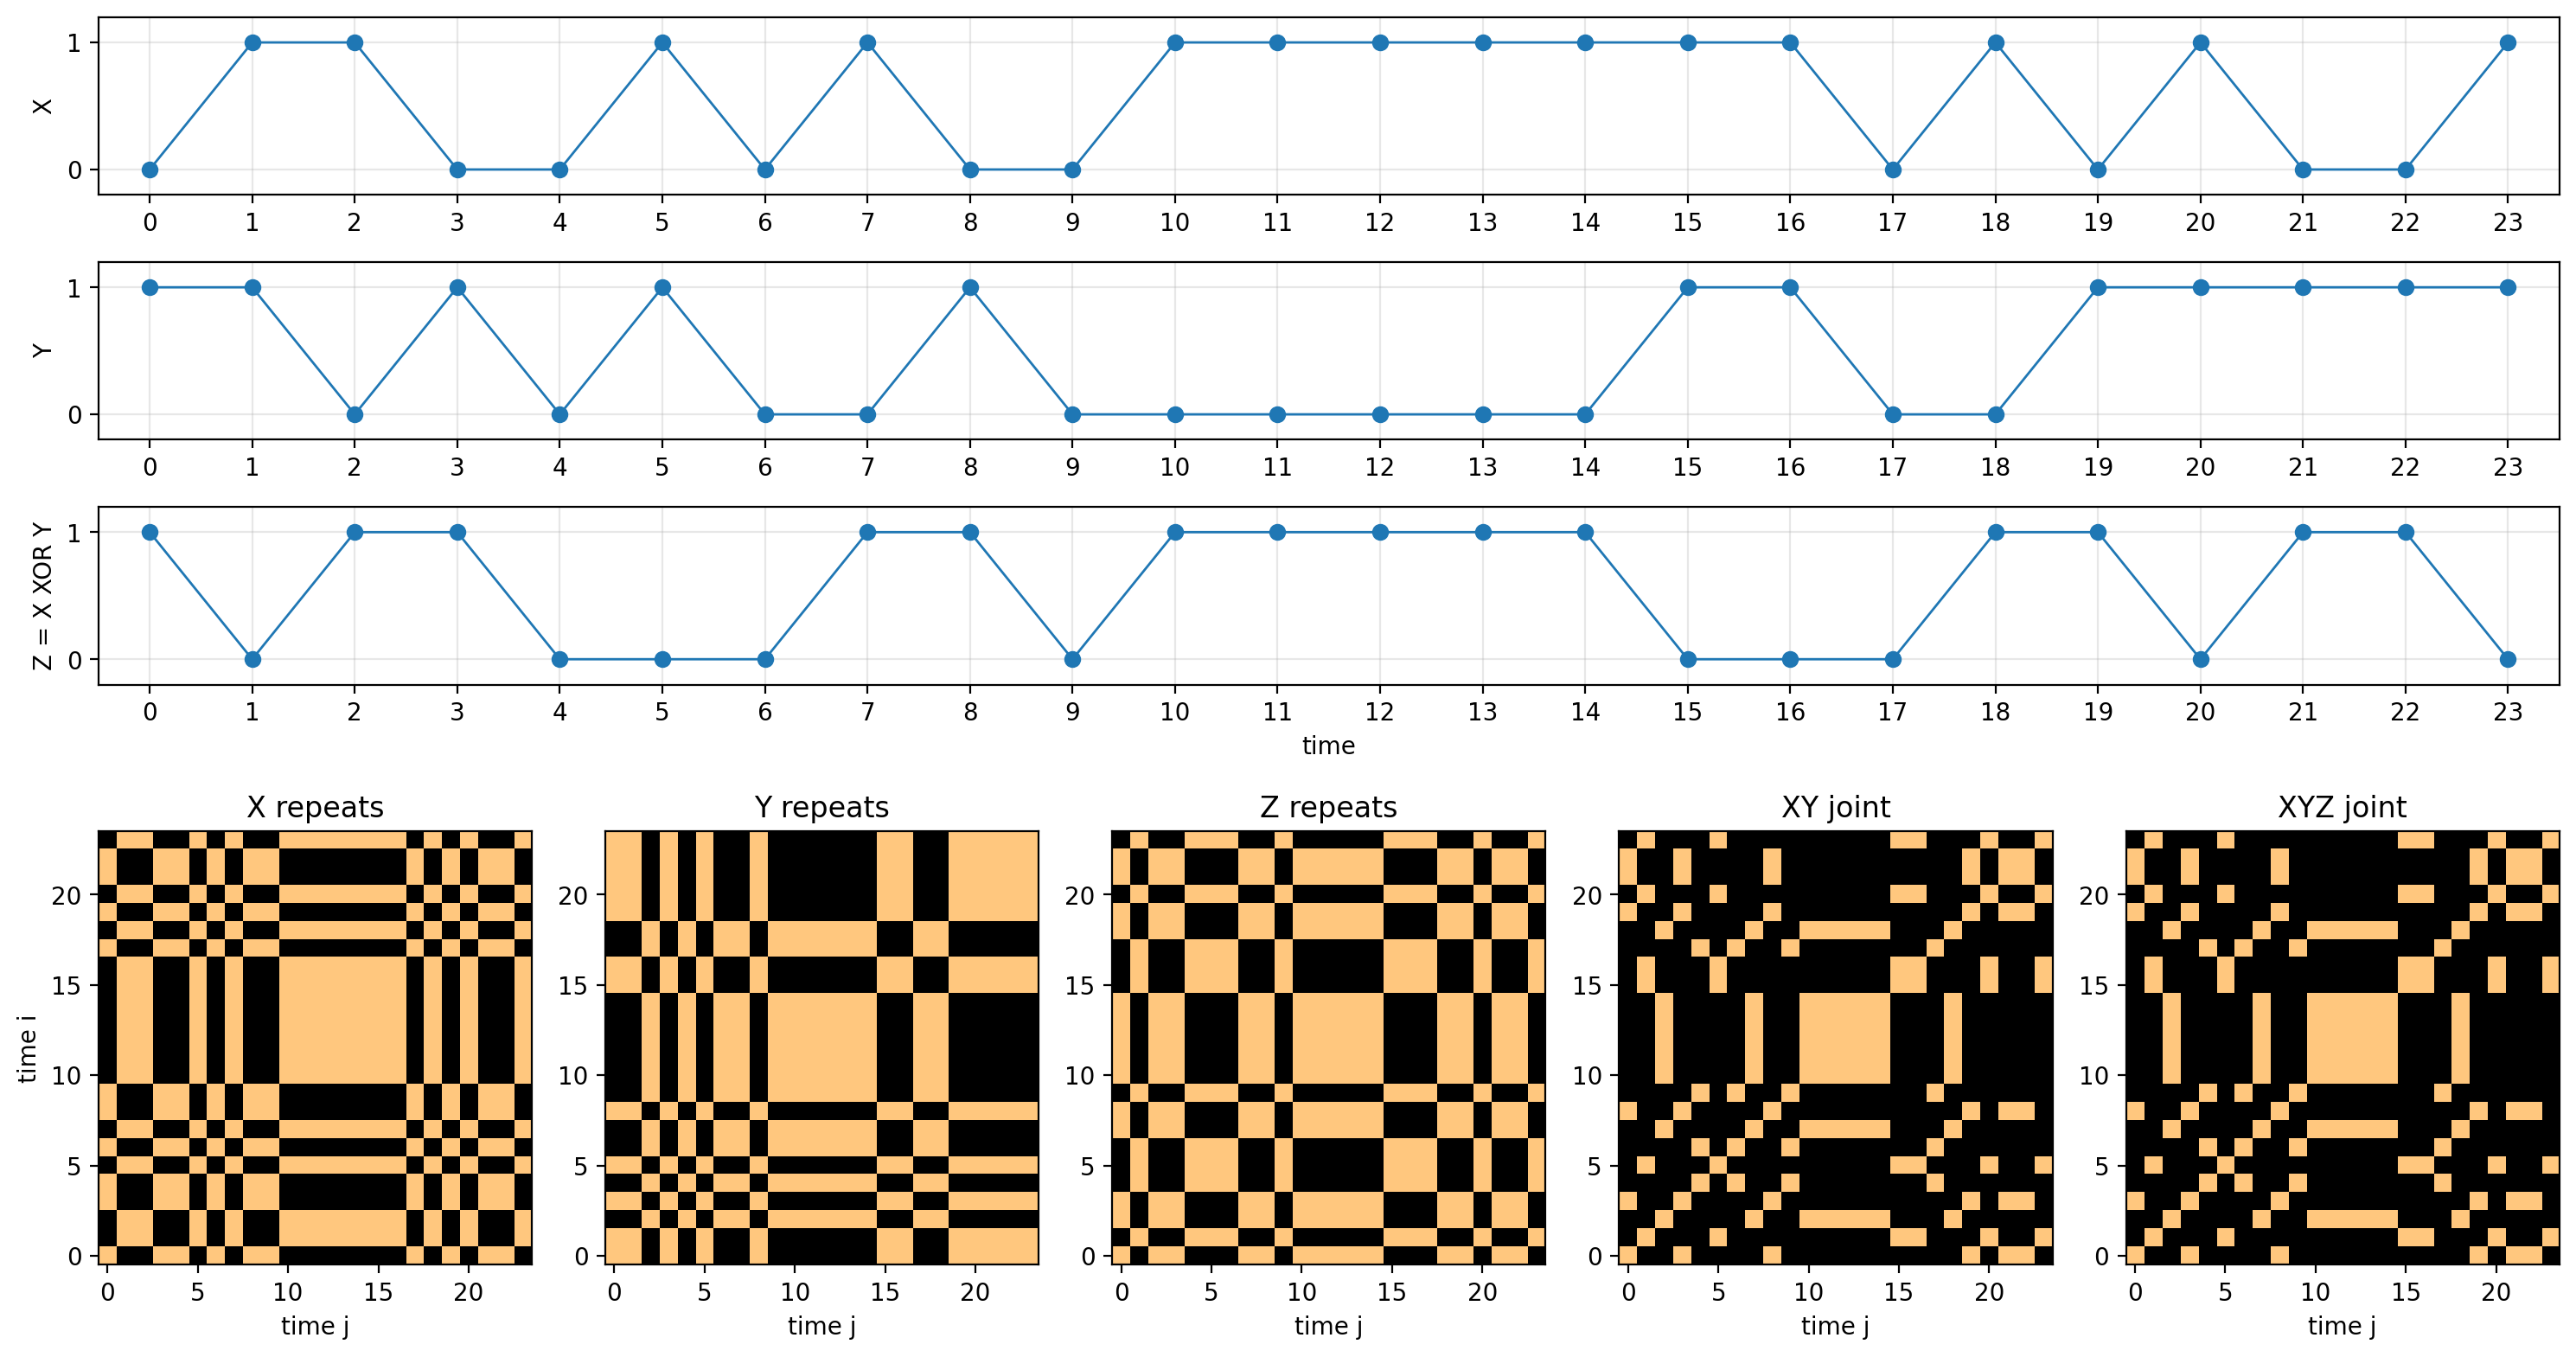

XY and XYZ joint matrices identical: True
XY joint rate:  0.2495
XYZ joint rate: 0.2495
XY recurrences rejected by adding Z: 0


In [6]:
rng = np.random.default_rng(42)
X = rng.integers(0, 2, 400)
Y = rng.integers(0, 2, 400)
Z = X ^ Y

RX = X[:, None] == X[None, :]
RY = Y[:, None] == Y[None, :]
RZ = Z[:, None] == Z[None, :]
JXY = RX & RY
JXYZ = JXY & RZ

n_show = 24
time = np.arange(n_show)
fig = plt.figure(figsize=(15, 8))
grid = fig.add_gridspec(4, 5, height_ratios=[0.6, 0.6, 0.6, 2])

for row, (label, series) in enumerate([('X', X), ('Y', Y), ('Z = X XOR Y', Z)]):
    ax = fig.add_subplot(grid[row, :])
    ax.plot(time, series[:n_show], marker='o', linewidth=1)
    ax.set_ylabel(label)
    ax.set_yticks([0, 1])
    ax.set_ylim(-0.2, 1.2)
    ax.set_xlim(-0.5, n_show - 0.5)
    ax.set_xticks(time)
    ax.grid(alpha=0.3)
    if row == 2:
        ax.set_xlabel('time')

for col, (title, matrix) in enumerate(zip(
    ['X repeats', 'Y repeats', 'Z repeats', 'XY joint', 'XYZ joint'],
    [RX, RY, RZ, JXY, JXYZ],
)):
    ax = fig.add_subplot(grid[3, col])
    ax.imshow(matrix[:n_show, :n_show], origin='lower', cmap='copper', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('time j')
    if col == 0:
        ax.set_ylabel('time i')
plt.tight_layout()
plt.show()

pairs = np.triu_indices(len(X), k=1)
print('XY and XYZ joint matrices identical:', np.array_equal(JXY, JXYZ))
print(f'XY joint rate:  {JXY[pairs].mean():.4f}')
print(f'XYZ joint rate: {JXYZ[pairs].mean():.4f}')
print('XY recurrences rejected by adding Z:', np.count_nonzero(JXY & ~RZ))

## D3

Each individual population recurrence probability is 1/2. Under mutual independence, we would expect \[P(X = X',\, Y = Y',\, Z = Z') =\] $(1/2)^3=1/8$ for all three to recur. XOR instead gives 1/4 because repeating both inputs guarantees repeating the output.

Thus $D_3=1/4-1/8=1/8$ : 
**12.5 percentage points above the independence baseline**. This score alone does not establish a genuine three-way interaction; copying one variable can also raise it.